In [166]:
import random

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [167]:
# read in all the words
words = open("../data/names.txt", "r").read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [168]:
len(words)

32033

In [169]:
# build the characters vocabulary and mappings to/from integers
chars = sorted(list(set("".join(words))))
stoi = {ch: i + 1 for i, ch in enumerate(chars)}
stoi["."] = 0
itos = {i: ch for ch, i in stoi.items()}
vocab_size = len(itos)
vocab_size

27

In [170]:
# build the dataset
block_size = 3  # context length: how many characters do we take to predict the next one


def build_dataset(words):
    X, Y = [], []

    for w in words:
        context = [0] * block_size  # context, starting with 3 start characters '...'
        for ch in w + ".":  # ending each word with end character '.'
            ix = stoi[ch]
            X.append(context)
            Y.append(stoi[ch])
            context = context[1:] + [ix]

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(f"X.shape: {X.shape}; Y.shape: {Y.shape}")
    return X, Y


random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))  # 80% mark
n2 = int(0.9 * len(words))  # 90% mark

# split dataset: 80% train, 10% dev, 10% test
Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

X.shape: torch.Size([182625, 3]); Y.shape: torch.Size([182625])
X.shape: torch.Size([22655, 3]); Y.shape: torch.Size([22655])
X.shape: torch.Size([22866, 3]); Y.shape: torch.Size([22866])


In [171]:
# MLP
n_emb = 10  # the dimensionality of the character embedding vectors
n_hidden = 200  # the number of neurons in the hidden layer of the MLP
n_input = block_size * n_emb  # number of inputs

seed = 2147483647
g = torch.Generator().manual_seed(seed)  # for reproducibility
C = torch.randn((vocab_size, n_emb), generator=g)  # embeddings lookup
W1 = torch.randn((n_input, n_hidden), generator=g)
b1 = torch.randn(n_hidden, generator=g)
W2 = torch.randn((n_hidden, vocab_size), generator=g)
b2 = torch.rand(vocab_size, generator=g)

parameters = [C, W1, b1, W2, b2]
n_params = sum(p.nelement() for p in parameters)  # number of parameters in MLP

# allow gradients for backward pass
for p in parameters:
    p.requires_grad = True

n_params

11897

In [172]:
C.shape, C[0, :], Xtr.shape, Xtr[0, 0], C[Xtr[0, 0]], C[Xtr[0]], C[Xtr[0]].shape

(torch.Size([27, 10]),
 tensor([ 1.5674, -0.2373, -0.0274, -1.1008,  0.2859, -0.0296, -1.5471,  0.6049,
          0.0791,  0.9046], grad_fn=<SelectBackward0>),
 torch.Size([182625, 3]),
 tensor(0),
 tensor([ 1.5674, -0.2373, -0.0274, -1.1008,  0.2859, -0.0296, -1.5471,  0.6049,
          0.0791,  0.9046], grad_fn=<SelectBackward0>),
 tensor([[ 1.5674, -0.2373, -0.0274, -1.1008,  0.2859, -0.0296, -1.5471,  0.6049,
           0.0791,  0.9046],
         [ 1.5674, -0.2373, -0.0274, -1.1008,  0.2859, -0.0296, -1.5471,  0.6049,
           0.0791,  0.9046],
         [ 1.5674, -0.2373, -0.0274, -1.1008,  0.2859, -0.0296, -1.5471,  0.6049,
           0.0791,  0.9046]], grad_fn=<IndexBackward0>),
 torch.Size([3, 10]))

In [173]:
# training

max_steps = 200_000
batch_size = 32
lossi = []

for i in range(max_steps):

    # mini batch
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]  # batch X, Y

    # forward pass
    emb = C[Xb]  # embed characters into vectors
    embcat = emb.view(emb.shape[0], -1)  # concatenate the vectors
    hpreact = embcat @ W1 + b1  # hidden layer pre-activation
    h = torch.tanh(hpreact)  # hidden layer
    logits = hpreact @ W2 + b2  # output layer
    loss = F.cross_entropy(logits, Yb)  # loss function

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100_000 else 0.01  # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10_000 == 0:  # print every 10_000th iteration
        print(f"{i:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())

      0/ 200000: 142.8037
  10000/ 200000: 2.2365
  20000/ 200000: 2.0312
  30000/ 200000: 2.6363
  40000/ 200000: 2.4554
  50000/ 200000: 2.7831
  60000/ 200000: 2.3067
  70000/ 200000: 2.0928
  80000/ 200000: 2.5090
  90000/ 200000: 2.4031
 100000/ 200000: 2.4590
 110000/ 200000: 2.3840
 120000/ 200000: 1.9893
 130000/ 200000: 2.2859
 140000/ 200000: 2.2671
 150000/ 200000: 2.4428
 160000/ 200000: 2.5257
 170000/ 200000: 2.0016
 180000/ 200000: 2.2091
 190000/ 200000: 2.2805


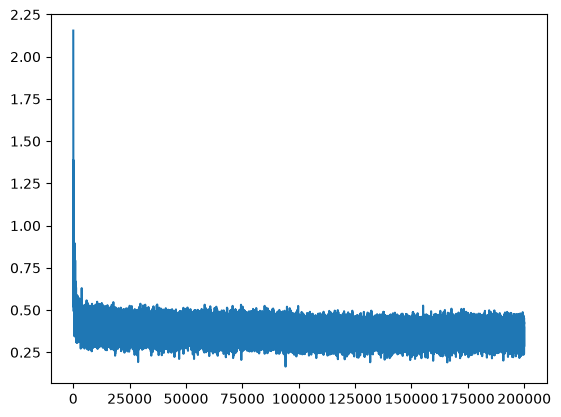

In [174]:
plt.plot(lossi)

In [175]:
# loss analysis (validation, test)


@torch.no_grad()  # disable gradient tracking (no need after the training)
def split_loss(split):
    x, y = {"train": (Xtr, Ytr), "val": (Xdev, Ydev), "test": (Xte, Yte)}[split]

    emb = C[x]  # (N, block_size, n_emb)
    embcat = emb.view(emb.shape[0], -1)  # concat to (N, block_size * n_emb)
    h = torch.tanh(embcat @ W1 + b1)  # (N, n_hidden)
    logits = h @ W2 + b2  # (n_hidden, vocab_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())


split_loss("train")
split_loss("val")

train 2.3876750469207764
val 2.3890929222106934


In [176]:
# sample the model

g = torch.Generator().manual_seed(seed + 10)

for _ in range(20):

    out = []
    context = [0] * block_size  # initialize with all ...

    while True:  # forward pass the neural net
        emb = C[torch.tensor([context])]  # (1, block_size, n_emb)
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)

        # sample from the distribution
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()

        # shift the context window and track the samples
        context = context[1:] + [ix]
        out.append(ix)

        if ix == 0:  # special token '.', break
            break

    # decode and print the generated word
    gen_word = "".join([itos[i] for i in out])
    print(gen_word)

carpahfaulyle.
khiemrri.
tatya.
kandene.
maceen.
ameryat.
kaqciborlenia.
ceriiv.
kaleigph.
bmynowa.
qaibn.
sroin.
alia.
bicoroelly.
jaryni.
fine.
piruaton.
dedoia.
gtafery.
frovaras.
